# Динамическое ценообразование авиабилетов - ML-часть кейса

**Выполнил: Гутенко Иван Никитич**

В ML-части кейса вы научитесь работать с данными с помощью **pandas**, обучать модели прогнозирования временных рядов
с помощью **AutoGluon** и честно проверять их качество.

## Постановка задачи

Мы хотим выставлять на авиабилеты разные цены в зависимости от ситуации, чтобы получать наибольшую прибыль. Для этого
нужно понимать, сколько людей захотят купить билет по нашей цене. Поэтому мы будем прогнозировать **спрос при базовой
цене**: сколько человек захотят полететь в конкретный день, если билет стоит как обычно.

Будем считать, что у людей есть **чувствительность к цене (эластичность)**: если поднять цену на N рублей, часть
желающих откажется от покупки. Наши аналитики уже посчитали эти значения для каждого маршрута. Ещё при подборе цены
нужно помнить, что **мест в самолёте ограниченное количество**, и продать билеты абсолютно всем желающим мы не можем.

Будущее сложно предсказать точно, поэтому моделью мы будем предсказывать не одно число, а **квантили** - прогнозы для разных сценариев.

**Квантиль q** - это значение, ниже которого настоящий спрос окажется с вероятностью q:
- **квантиль 0.1** - пессимистичный сценарий: спрос окажется ниже этого числа только в 10% случаев, а в 90% - выше;
- **квантиль 0.5 (медиана)** -  спрос с равной вероятностью окажется выше или ниже;
- **квантиль 0.9** - оптимистичный сценарий: спрос превысит это число только в 10% случаев.

Например, для рейса Москва - Сочи на 12 июня модель может выдать:

| квантиль | 0.1 | 0.3 | 0.5 | 0.7 | 0.9 |
|---|---|---|---|---|---|
| спрос, человек | 744 | 830 | 888 | 946 | 1032 |

Из квантилей строятся **интервалы**. Диапазон от квантиля 0.1 до квантиля 0.9 - это **80%-й интервал**: с вероятностью
80% настоящий спрос окажется между 744 и 1032. Чем шире интервал, тем меньше модель уверена в прогнозе.

Для бизнеса важно получить не одну цену, а **распределение цены**, чтобы понимать, насколько модель уверена. Если разброс
цен слишком большой, на ситуацию стоит взглянуть дополнительно и выбрать менее рискованный вариант.

Для каждого сценария спроса можно посчитать свою лучшую цену: чем больше спрос, тем выше цена. Так из квантилей спроса
получается **распределение цены**, которое и нужно бизнесу.

## Данные

**`train.csv`** - история спроса с 1 января 2022 по 30 апреля 2026, на ней обучаем модели.
**`test.csv`** - спрос за май 2026, только для финальной проверки выбранной модели.

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута, например `MOW-AER` (Москва - Сочи) |
| `demand` | спрос: сколько человек купили бы билет в этот день по базовой цене |

**`routes.csv`** - справочник маршрутов:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `name` | города, например Москва - Сочи |
| `base_price` | базовая цена билета, ₽ |
| `cost_per_passenger` | наши расходы на одного пассажира, ₽ |
| `price_sensitivity` | чувствительность к цене: сколько пассажиров теряем на каждый +1 ₽ цены |
| `price_min`, `price_max` | допустимый диапазон цены, ₽ |

**`schedule.csv`** - расписание на май–июль 2026:

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута |
| `seats` | сколько всего мест в самолётах на этом маршруте в этот день |

## Как работать

Если непонятно, как устроена функция или метод, загляните в документацию: [pandas](https://pandas.pydata.org/docs/),
[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html), [matplotlib](https://matplotlib.org/stable/).
Можно спросить и у ИИ-ассистента, но не злоупотребляйте: важно, чтобы вы понимали, что вы делаете.

Описание любой функции можно посмотреть прямо в ноутбуке: поставьте `?` после её названия и запустите ячейку.
Пример - в ячейке ниже.

In [1]:
import pandas as pd

pd.read_csv?

## Подготовка

Запустите ячейку ниже. В Google Colab она установит AutoGluon и скачает данные кейса - это займёт несколько минут.
Если после установки Colab попросит перезапустить сеанс (Restart session), перезапустите и запустите эту ячейку ещё раз.

In [2]:
import os, sys, zipfile, urllib.request

IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = "../../data/ml_case/public/"                    # путь к данным при запуске из репозитория кейса

if IN_COLAB:
    !uv pip install autogluon.timeseries --extra-index-url https://download.pytorch.org/whl/cpu   # в Colab AutoGluon не установлен

if IN_COLAB or not os.path.exists(LOCAL_DATA):
    url = "https://gist.githubusercontent.com/Murkat-git/3ddc868889d3e0d37542d786c8b1aa74/raw/reshis_case_data.zip"
    urllib.request.urlretrieve(url, "reshis_case_data.zip")                  # скачиваем архив с данными
    zipfile.ZipFile("reshis_case_data.zip").extractall()                    # распаковываем в папку data/
    DATA_DIR = "data/"
else:
    DATA_DIR = LOCAL_DATA

print("Запуск в Colab" if IN_COLAB else "Запуск на своём компьютере", "- данные в папке", DATA_DIR)

Запуск на своём компьютере - данные в папке data/


In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["date"])
routes = pd.read_csv(DATA_DIR + "routes.csv")
train.head()

,date,route,demand
0,2022-01-01,MOW-AER,221
1,2022-01-02,MOW-AER,242
2,2022-01-03,MOW-AER,438
3,2022-01-04,MOW-AER,406
4,2022-01-05,MOW-AER,397


## Задание 1. Исследование данных

**1.1.** Посмотрите на данные глазами: постройте графики изменения спроса по датам для каждого маршрута. Вам может помочь
метод `.plot()` у pandas DataFrame или функции из matplotlib / seaborn.

**1.2.** Видите ли вы в данных что-то необычное? Резкие скачки, провалы, изменения уровня? Как вы думаете, это шум или
что-то полезное для модели? Подумайте, что могло происходить в такие дни: это поможет на следующих этапах.

**Результат задания:** графики спроса по каждому маршруту и текстовый ответ: что необычного вы нашли в данных и что,
по-вашему, происходило в эти дни.

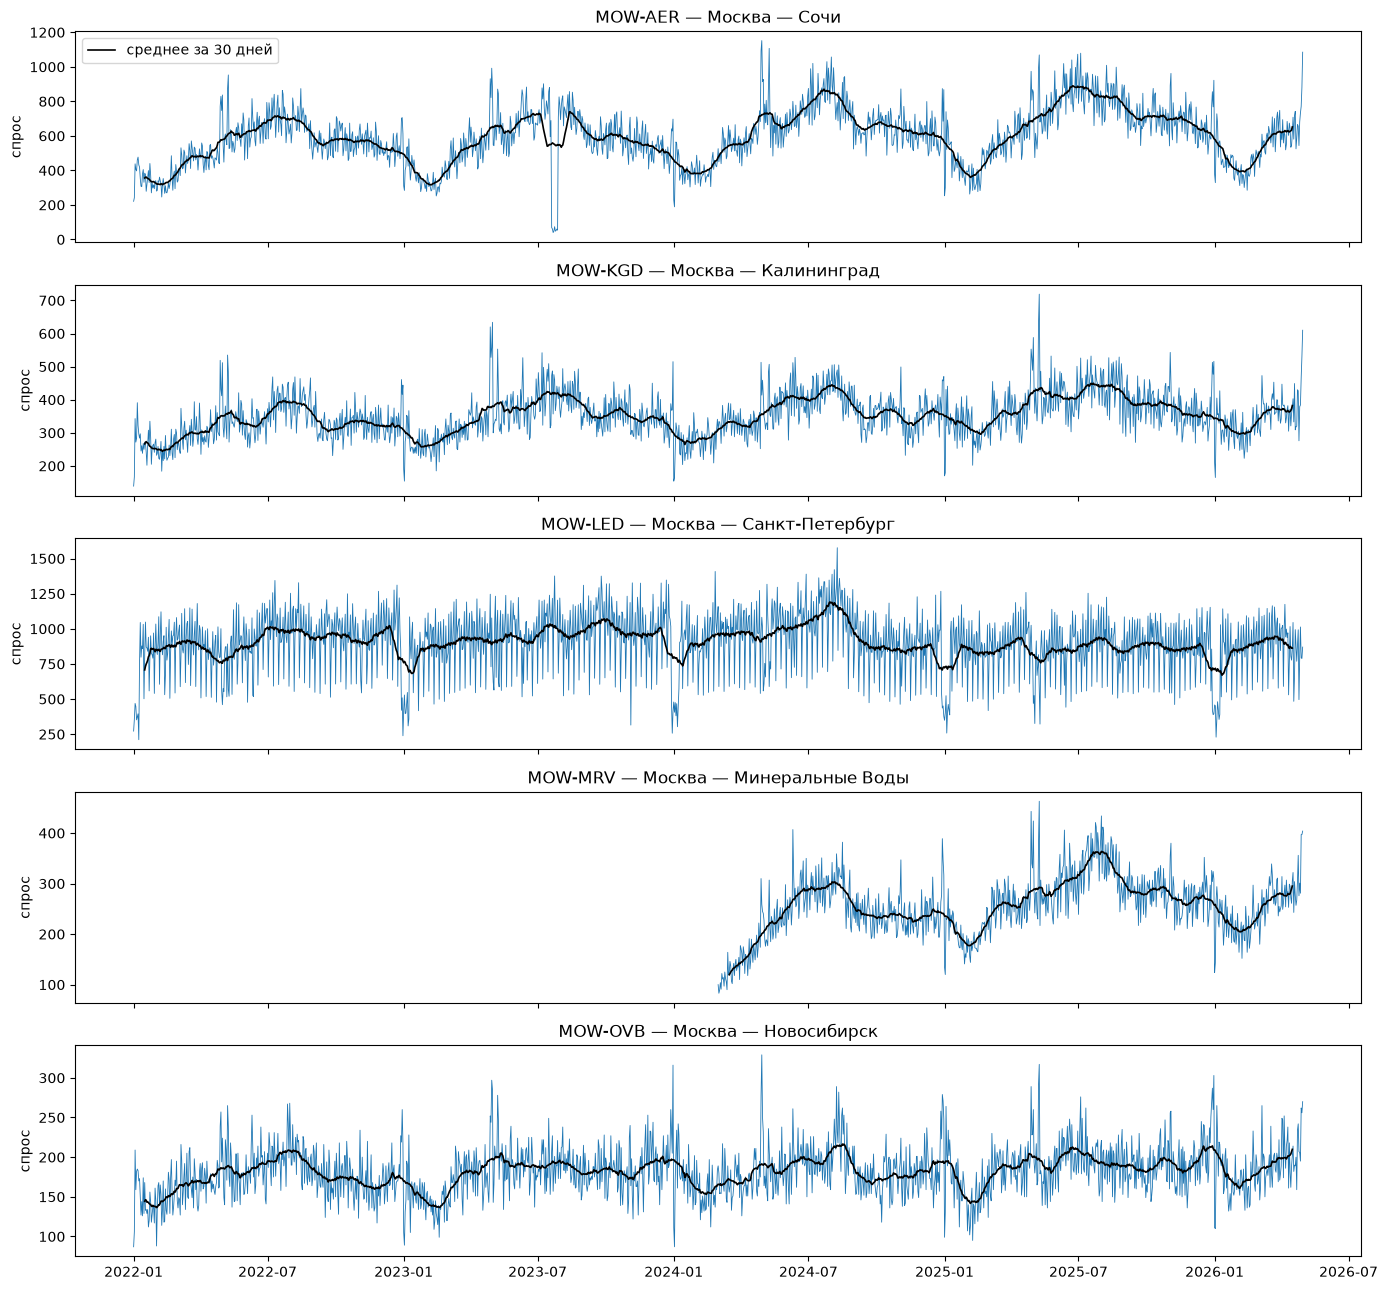

Начало и конец рядов:
               min        max  count
route                               
MOW-AER 2022-01-01 2026-04-30   1581
MOW-KGD 2022-01-01 2026-04-30   1581
MOW-LED 2022-01-01 2026-04-30   1581
MOW-MRV 2024-03-01 2026-04-30    791
MOW-OVB 2022-01-01 2026-04-30   1581

Средний спрос по дням недели:
route  MOW-AER  MOW-KGD  MOW-LED  MOW-MRV  MOW-OVB
Пн       626.0    366.0   1080.0    269.0    190.0
Вт       525.0    311.0    901.0    231.0    161.0
Ср       555.0    325.0    879.0    239.0    170.0
Чт       627.0    374.0    945.0    272.0    194.0
Пт       642.0    379.0   1066.0    272.0    196.0
Сб       551.0    322.0    563.0    233.0    166.0
Вс       649.0    384.0    876.0    270.0    196.0

Даты, где спрос в среднем по годам отличается от обычного (1.0 = обычный день):
route  MOW-AER  MOW-KGD  MOW-LED  MOW-MRV  MOW-OVB
date                                              
01-01     0.60     0.56     0.48     0.57     0.62
01-02     0.62     0.55     0.45     0.55     

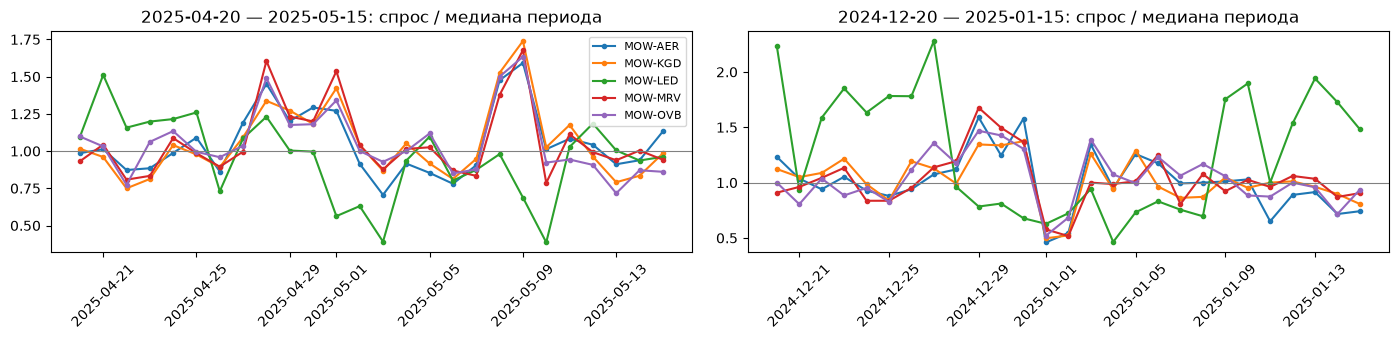

In [4]:
# Ваш код здесь
routes_list = sorted(train["route"].unique())
names = dict(zip(routes["route"], routes["name"]))

# 1.1. Вся история по каждому маршруту
fig, axes = plt.subplots(len(routes_list), 1, figsize=(14, 2.6 * len(routes_list)), sharex=True)
for ax, r in zip(axes, routes_list):
    s = train[train["route"] == r].set_index("date")["demand"]
    ax.plot(s.index, s, lw=0.6)
    ax.plot(s.rolling(30, center=True).mean(), color="black", lw=1.2, label="среднее за 30 дней")
    ax.set_title(f"{r} — {names[r]}"); ax.set_ylabel("спрос")
axes[0].legend()
plt.tight_layout(); plt.show()

print("Начало и конец рядов:")
print(train.groupby("route")["date"].agg(["min", "max", "count"]))

# Недельный узор: средний спрос по дням недели
dow = train.assign(dow=train["date"].dt.dayofweek).pivot_table(index="dow", columns="route", values="demand")
dow.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
print("\nСредний спрос по дням недели:"); print(dow.round(0))

# 1.2. Аномальные дни: отношение спроса к «обычному» уровню этого же дня недели (медиана ±5 недель)
def ratio_to_normal(s):
    out = s * np.nan
    for d in range(7):
        ss = s[s.index.dayofweek == d]
        out[ss.index] = ss / ss.rolling(11, center=True, min_periods=4).median()
    return out

wide = train.pivot(index="date", columns="route", values="demand")
ratio = wide.apply(ratio_to_normal)
by_date = ratio.groupby(ratio.index.strftime("%m-%d")).mean()
unusual = by_date[(by_date.sub(1).abs() > 0.18).sum(axis=1) >= 3]
print("\nДаты, где спрос в среднем по годам отличается от обычного (1.0 = обычный день):")
print(unusual.round(2))

# Пример: майские праздники и Новый год крупно
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (a, b) in zip(axes, [("2025-04-20", "2025-05-15"), ("2024-12-20", "2025-01-15")]):
    part = wide.loc[a:b]
    for r in routes_list:
        ax.plot(part.index, part[r] / part[r].median(), marker=".", label=r)
    ax.axhline(1, color="gray", lw=0.8); ax.set_title(f"{a} — {b}: спрос / медиана периода")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Ваш ответ:** Что необычного вы нашли в данных? Это шум или что-то полезное для модели? Что, по-вашему, происходило в эти дни?

1. **Годовая сезонность.** У туристических направлений (Сочи, Калининград, Мин. Воды) спрос летом примерно в 1,5–2 раза выше, чем в январе–феврале. У Новосибирска и Петербурга сезонность слабая.
2. **Недельный узор.** Особенно сильный у Москва – Петербург: в понедельник и пятницу около 1060–1080, в субботу около 560. Это деловой маршрут: люди летят в начале и в конце рабочей недели.
3. **Праздники — повторяются каждый год в одни и те же даты** (таблица выше; 1.0 — обычный уровень этого дня недели):
   - на туристических маршрутах **пики в канун длинных выходных**: 28–30 апреля и 1 мая (×1,4–1,6), 8–9 мая, 10–11 июня, 2–3 ноября, 29–31 декабря, а также 8 января;
   - **1–2 января провал** (×0,5–0,6) на всех маршрутах;
   - у **Москва – Петербург всё наоборот**: в праздничные нерабочие дни спрос падает (весь период 1–8 января ×0,45, 1–3 и 9–10 мая, 12 июня, 4 ноября, 29–31 декабря ×0,45–0,65). Командировок нет, поэтому праздник для этого маршрута как выходной. После каникул (9 января) — резкий всплеск: все возвращаются на работу.
4. **Разовые события, которые не повторяются:**
   - Сочи, 20–28 июля 2023: спрос рухнул с ~600 до 40–70 человек в день, вероятно, из-за закрытия аэропорта или ограничений полётов;
   - Москва – Петербург: летом 2024 всплеск (+20%), затем с сентября 2024 уровень снизился с ~950 до ~850 и так и остался. Похоже на появление конкурента (например, другой авиакомпании или поезда).
5. **Мин. Воды** — новый маршрут: данные с марта 2024, первые месяцы спрос растёт с ~100 до ~300 (маршрут «раскручивается»).

**Шум или польза?** Праздники — **полезный сигнал**: их даты известны заранее, поэтому их можно передать модели как признаки (задание 3), и она будет предсказывать пики и провалы. Провал в Сочи в июле 2023 — **выброс**: предсказать его нельзя, и он может только сбить модель (например, SeasonalNaive на 2024 год). Сдвиг уровня Петербурга важен для модели: смотреть надо на свежий уровень, а не на средний за все годы. Модели, которые учитывают последние значения ряда, это делают сами.


## Задание 2. Обучение моделей в AutoGluon

[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html) - библиотека, которая умеет обучать сразу много
моделей прогнозирования временных рядов и сравнивать их между собой. Подробнее - в
[быстром старте](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-quick-start.html).

Шпаргалка по основным вызовам (из документации AutoGluon):

```python
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# 1) данные: длинная таблица - по строке на каждый ряд и момент времени
data = TimeSeriesDataFrame.from_data_frame(df, id_column="item_id", timestamp_column="timestamp")

# 2) предиктор
predictor = TimeSeriesPredictor(
    prediction_length=48,              # на сколько шагов вперёд прогнозировать
    target="target",                   # какую колонку прогнозируем
    eval_metric="MASE",                # как считаем ошибку
    quantile_levels=[0.1, 0.5, 0.9],   # какие квантили выдавать
    path="autogluon-models",           # куда сохранять модели
)

# 3а) обучение готовым набором моделей - пресетом
predictor.fit(data, presets="medium_quality", time_limit=600)

# 3б) или списком конкретных моделей с параметрами
predictor.fit(data, hyperparameters={
    "SeasonalNaive": {},
    "DirectTabular": {},
    "Chronos": {"model_path": "bolt_small"},
})

# 4) таблица моделей: ошибка на валидации (score_val), время обучения и прогноза
predictor.leaderboard()

# 5) прогноз и график: история + прогноз с квантилями
predictions = predictor.predict(data)
predictor.plot(data, predictions, quantile_levels=[0.1, 0.9], max_history_length=200)

# 6) ошибка на тестовых данных (история + последние prediction_length шагов для проверки)
predictor.evaluate(test_data)
```

На что обратить внимание:
- **Длина прогноза.** Выберите её сами, исходя из длины тестовых данных.
- **Метрика.** Ошибку считаем по **MAE** (средняя абсолютная ошибка: на сколько пассажиров в среднем промахивается прогноз).
- **Квантили.** Модель должна выдавать квантили от 0.1 до 0.9: из них потом получится распределение цены.
- **Валидация.** AutoGluon сам откладывает последние дни обучающих данных как валидацию и сравнивает модели по ним.
  Тест (`test.csv`) пока **не трогаем**: он понадобится в самом конце.
- **Какие модели обучать.** Пресет - быстрый способ начать; список моделей и параметров даёт больше контроля.
  Какие есть пресеты и модели, смотрите в
  [описании моделей](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-model-zoo.html).

**2.1.** Обучите модели на `train`. Поэкспериментируйте с разными конфигурациями обучения (пресеты, наборы моделей,
их параметры) и выберите **конфигурацию**, которая даёт наименьшую ошибку на валидации.

**2.2.** Посмотрите на таблицу моделей (`leaderboard`) для выбранной конфигурации. Какая модель лучшая по валидации?
Как вы думаете, почему именно, как она работает? Насколько она лучше самой простой - `SeasonalNaive` (как в прошлом сезоне)?

**Результат задания:** обученные модели и таблица моделей (`leaderboard`) для лучшей конфигурации; текстовый ответ: какие
конфигурации вы пробовали, какая модель лучшая по валидации и почему, насколько она лучше `SeasonalNaive`.

In [5]:
# Ваш код здесь
# Результат: обученный predictor и таблица results_v1 = predictor.leaderboard()
# test пока не используем
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

PREDICTION_LENGTH = 31                       # тест - 31 день мая, прогноз для сервиса - 31 день (1 июня - 1 июля)
QUANTILE_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
NUM_VAL_WINDOWS = 3                          # 3 окна по 31 дню: оценка устойчивее, чем по одному месяцу

def to_ts(df):
    return TimeSeriesDataFrame.from_data_frame(
        df.rename(columns={"route": "item_id", "date": "timestamp"}), id_column="item_id", timestamp_column="timestamp")

train_ts = to_ts(train)

def make_predictor(path, **kw):
    return TimeSeriesPredictor(prediction_length=PREDICTION_LENGTH, target="demand", eval_metric="MAE",
                               quantile_levels=QUANTILE_LEVELS, path=path, verbosity=1, **kw)

# Конфигурация 1: пресет medium_quality (Chronos-2, Toto-2, DirectTabular, RecursiveTabular, ETS, Theta, SeasonalNaive + ансамбль)
# (пресет fast_training в AutoGluon 1.6 устарел и автоматически заменяется на medium_quality)
predictor_preset = make_predictor("ag-v1-preset")
predictor_preset.fit(train_ts, presets="medium_quality", time_limit=900, num_val_windows=NUM_VAL_WINDOWS)
lb_preset = predictor_preset.leaderboard()

# Конфигурация 2: свой набор моделей - Chronos-Bolt без дообучения и с дообучением на наших рядах
predictor_custom = make_predictor("ag-v1-custom")
predictor_custom.fit(train_ts, num_val_windows=NUM_VAL_WINDOWS, time_limit=1200, hyperparameters={
    "SeasonalNaive": {}, "ETS": {}, "Theta": {}, "DirectTabular": {}, "RecursiveTabular": {},
    "Chronos": [{"model_path": "bolt_small", "ag_args": {"name_suffix": "ZeroShot"}},
                {"model_path": "bolt_small", "fine_tune": True, "ag_args": {"name_suffix": "FineTuned"}}],
})
lb_custom = predictor_custom.leaderboard()

cols = ["model", "score_val", "fit_time_marginal", "pred_time_val"]
print("Конфигурация 1 (medium_quality):"); display(lb_preset[cols])
print("Конфигурация 2 (свой набор с Chronos-Bolt):"); display(lb_custom[cols])

# Выбираем конфигурацию с наименьшей ошибкой лучшей модели на валидации (score_val = -MAE, больше - лучше)
best = max([("medium_quality", predictor_preset, lb_preset), ("custom", predictor_custom, lb_custom)],
           key=lambda x: x[2]["score_val"].max())
print("Лучшая конфигурация:", best[0])
predictor, results_v1 = best[1], best[2]
results_v1[cols]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

... (8 outputs left out)

Конфигурация 2 (свой набор с Chronos-Bolt):


,model,score_val,fit_time_marginal,pred_time_val
0,WeightedEnsemble,-36.632295,0.421898,0.190366
1,DirectTabular,-38.264162,2.130579,0.043793
2,ChronosFineTuned[bolt_small],-38.821159,546.295979,0.074373
3,ChronosZeroShot[bolt_small],-40.110369,4.782931,2.226568
4,ETS,-48.757126,0.826210,0.336376
5,RecursiveTabular,-48.845732,2.388779,0.071225
6,Theta,-49.221816,0.252467,0.125319
7,SeasonalNaive,-51.539785,0.049930,0.014207


Лучшая конфигурация: medium_quality


,model,score_val,fit_time_marginal,pred_time_val
0,WeightedEnsemble,-35.465511,0.400646,0.157236
1,Chronos2,-36.646937,9.226033,0.111393
2,DirectTabular,-38.264162,1.947198,0.045255
3,Toto2,-42.419932,2.186243,0.022979
4,ETS,-48.757126,1.550879,0.448196
5,RecursiveTabular,-48.845732,2.149631,0.071772
6,Theta,-49.221816,0.263115,0.125569
7,SeasonalNaive,-51.539785,2.167214,0.014317


**Ваш ответ:** Какие конфигурации вы пробовали? Какая модель лучшая по валидации? Почему именно она, как она работает? Насколько она лучше SeasonalNaive?

**Конфигурации** (горизонт 31 день — как длина теста и июньского прогноза, метрика MAE, квантили 0.1…0.9, **3 окна валидации** по 31 дню, чтобы оценка не зависела от одного месяца):
1. пресет `medium_quality`: Chronos-2, Toto-2, DirectTabular, RecursiveTabular, ETS, Theta, SeasonalNaive + взвешенный ансамбль. Пресет `fast_training` в AutoGluon 1.6 устарел и автоматически заменяется на `medium_quality`, поэтому отдельно его не сравниваем;
2. свой набор моделей: Chronos-Bolt (small) без дообучения и **с дообучением** на наших рядах + DirectTabular, RecursiveTabular, ETS, Theta, SeasonalNaive.

**Лучшая конфигурация — `medium_quality`**: лучшая модель WeightedEnsemble, MAE = 35,5 (во второй конфигурации 36,5). Лучшая одиночная модель — **Chronos-2** (MAE 36,6). Дообученный Chronos-Bolt (38,5) обучался ~9 минут и всё равно хуже Chronos-2 без дообучения, который «обучается» за ~9 секунд.

**Почему Chronos-2.** Это предобученная «foundation»-модель (трансформер), которая видела огромное количество чужих временных рядов. Она по истории ряда сразу выдаёт квантили на будущее, без обучения на наших данных. Она сама замечает недельный узор, тренд и текущий уровень. Ансамбль ещё немного лучше: он усредняет Chronos-2 с DirectTabular (градиентный бустинг на лагах и календарных признаках), и их ошибки частично компенсируют друг друга.

**Насколько лучше SeasonalNaive:** MAE 35,5 (ансамбль) / 36,6 (Chronos-2) против 51,5 — **на 31% / 29% меньше ошибка**. SeasonalNaive просто повторяет прошлую неделю, поэтому не видит тренд и праздники и переносит случайный шум прошлой недели.


## Задание 3. Признаки: помогаем модели

Кроме истории наблюдений, у нас могут быть **дополнительные данные** о будущих днях, которые помогают прогнозу. Например:
- прогноз погоды;
- расписание крупных событий (концерты, спортивные матчи, фестивали);
- школьные каникулы;
- акции и распродажи, которые мы сами планируем.

Их можно передать модели как **признаки**. В AutoGluon они называются `known_covariates`, то есть признаки, известные
заранее: их значения должны быть известны и для будущих дат, на которые мы строим прогноз.

В наших данных таких дополнительных колонок нет, есть только даты. Но и из дат можно кое-что извлечь. Вспомните, что
необычного вы нашли в задании 1: некоторые скачки и провалы повторяются **каждый год в одни и те же даты**. Что это за
дни и можно ли знать их заранее?

**3.1.** Придумайте признаки, которые можно получить из даты, и напишите функцию **`add_features(df)`**, которая
добавляет их в таблицу с колонкой `date`.

Пример, как устроена такая функция (признак здесь просто для иллюстрации):

```python
def add_features(df):
    df = df.copy()
    month = df["date"].dt.month_name()     # название месяца по-английски: "January" … "December"
    day = df["date"].dt.day                # число месяца: 1–31

    # признак 1 сентября: 1 в этот день, иначе 0; условия объединяются через & (и) и | (или)
    df["sept_1"] = ((month == "September") & (day == 1)).astype(int)

    return df
```

**3.2.** Обучите модели заново с вашими признаками и сравните ошибку **на валидации** с заданием 2. Помогли ли признаки?
Каким моделям больше, каким меньше и почему? Сохраните таблицу моделей в **`results_v2`**.

Подсказки по AutoGluon:
- при создании предиктора укажите `known_covariates_names=[...]` - список названий ваших признаков;
- признаки должны быть в данных для обучения **и** для будущих дат: при прогнозе их передают через
  `predictor.predict(data, known_covariates=...)`;
- день недели и день года AutoGluon добавляет сам - их придумывать не нужно.

**Результат задания:** функция `add_features(df)`, модели, обученные с признаками, и сравнение ошибки на валидации
с заданием 2; текстовый ответ: какие признаки вы придумали и почему, помогли ли они и каким моделям.

In [6]:
# Ваш код здесь
# Результат: функция add_features(df), обученный predictor с признаками, таблица results_v2
DAYS_OFF = {"01-01", "01-02", "01-03", "01-04", "01-05", "01-06", "01-07", "01-08",    # новогодние каникулы
            "02-23", "03-08", "05-01", "05-02", "05-03", "05-09", "05-10", "06-12", "11-04",
            "12-29", "12-30", "12-31"}
PRE_HOLIDAY = {"12-29", "12-30", "12-31", "04-28", "04-29", "04-30", "05-01", "05-08", "05-09",
               "06-10", "06-11", "11-02", "11-03", "02-22", "03-07", "01-08"}
FEATURES = ["day_off", "pre_holiday", "new_year_dip", "back_to_work"]

def add_features(df):
    df = df.copy()
    md = df["date"].dt.strftime("%m-%d")
    df["day_off"] = md.isin(DAYS_OFF).astype(int)            # нерабочий праздничный день: деловые поездки падают
    df["pre_holiday"] = md.isin(PRE_HOLIDAY).astype(int)     # канун длинных выходных: все улетают отдыхать
    df["new_year_dip"] = md.isin({"01-01", "01-02"}).astype(int)   # 1-2 января почти никто не летит
    df["back_to_work"] = (md == "01-09").astype(int)         # первый рабочий день после каникул
    return df

def to_ts_feat(df):
    ts = to_ts(add_features(df))
    # статический признак маршрута: деловой (Москва - Петербург) реагирует на праздники наоборот
    ts.static_features = pd.DataFrame({"business_route": [int(i == "MOW-LED") for i in ts.item_ids]}, index=ts.item_ids)
    return ts

train_ts_feat = to_ts_feat(train)
predictor = make_predictor("ag-v2", known_covariates_names=FEATURES)
predictor.fit(train_ts_feat, presets="medium_quality", time_limit=900, num_val_windows=NUM_VAL_WINDOWS)
results_v2 = predictor.leaderboard()

compare = (results_v1.set_index("model")[["score_val"]].rename(columns={"score_val": "MAE без признаков"})
           .join(results_v2.set_index("model")[["score_val"]].rename(columns={"score_val": "MAE с признаками"}), how="outer"))
compare = -compare                                   # score_val = -MAE, переводим в обычную MAE
compare["улучшение, %"] = (1 - compare["MAE с признаками"] / compare["MAE без признаков"]) * 100
compare.sort_values("MAE с признаками").round(2)

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

,MAE без признаков,MAE с признаками,"улучшение, %"
model,,,
WeightedEnsemble,35.47,34.29,3.32
Chronos2,36.65,35.86,2.14
DirectTabular,38.26,36.25,5.26
Toto2,42.42,42.42,0.00
RecursiveTabular,48.85,46.02,5.80
ETS,48.76,48.76,0.00
Theta,49.22,49.22,0.00
SeasonalNaive,51.54,51.54,0.00


**Ваш ответ:** Какие признаки вы придумали и почему? Помогли ли они? Каким моделям больше, каким меньше и почему?

**Признаки** (все известны заранее, потому что зависят только от даты):
- `day_off` — праздничные нерабочие дни (новогодние каникулы 1–8 января, 23 февраля, 8 марта, 1–3 и 9–10 мая, 12 июня, 4 ноября, 29–31 декабря): в эти дни падают деловые поездки (Петербург);
- `pre_holiday` — канун длинных выходных (28 апреля – 1 мая, 8–9 мая, 10–11 июня, 2–3 ноября, 29–31 декабря, 22 февраля, 7 марта, 8 января): пики на туристических маршрутах;
- `new_year_dip` — 1–2 января, когда почти никто не летит;
- `back_to_work` — 9 января, возвращение после каникул (всплеск у Петербурга);
- статический признак маршрута `business_route` (1 у Москва – Петербург): на праздники он реагирует противоположно остальным, и модели нужно это различать.

Даты взяты из анализа в задании 1: эти дни повторялись каждый год.

**Помогли ли:** да. Ошибка ансамбля на валидации снизилась с 35,5 до **34,3** (−3,3%), у Chronos-2 — с 36,6 до 35,9 (−2,1%), у DirectTabular — с 38,3 до 36,2 (−5,3%), у RecursiveTabular — с 48,8 до 46,0 (−5,8%).

**Каким моделям больше, каким меньше и почему.** Больше всего выиграли **табличные модели** (DirectTabular, RecursiveTabular): это градиентный бустинг, который строит прогноз из признаков, и новые признаки для него — прямая информация. Chronos-2 выиграл меньше: он и так хорошо ловит узоры из истории, а признаки использует как дополнительную подсказку. **ETS, Theta, SeasonalNaive и Toto-2 признаки не используют вообще**, поэтому их ошибка не изменилась. Прирост умеренный ещё и потому, что в окнах валидации (февраль–апрель) мало праздников. Основная польза будет в праздничные периоды: майские, 12 июня, Новый год.


## Задание 4. Выберите модель для бизнеса

Самая точная модель - не всегда лучшая для бизнеса. Посмотрите на `results_v2`: ошибку на валидации (`score_val`),
время обучения (`fit_time_marginal`) и время прогноза (`pred_time_val`).

**4.1.** Какая модель даёт лучшее соотношение **качество / скорость**? Посмотрите, сколько времени модели обучаются
и строят прогноз. Возможно, есть модель, которая немного уступает самой точной по качеству, но работает заметно быстрее.

**4.2.** Какую модель вы предложите авиакомпании и почему? Учтите, насколько быстро модель обучается и строит прогноз.
Запишите выбор в **`final_model`** (название модели).

**Результат задания:** выбранная модель в переменной `final_model`; текстовый ответ: почему вы выбрали именно её с учётом
качества и скорости.

In [7]:
# Ваш код здесь
# Например: final_model = "SeasonalNaive"
table = results_v2[["model", "score_val", "fit_time_marginal", "pred_time_val"]].copy()
table["MAE"] = -table["score_val"]
table["хуже лучшей, %"] = (table["MAE"] / table["MAE"].min() - 1) * 100
display(table.drop(columns="score_val").round(3))

# MAE оценивает только медиану, а сервис строит цены по всем 9 квантилям.
# Проверим качество квантилей на последнем окне валидации (апрель 2026, тест не трогаем):
# WQL - взвешенная квантильная ошибка (меньше - лучше), покрытие 80%-го интервала (идеал - 0.8).
hist = train_ts_feat.slice_by_timestep(None, -PREDICTION_LENGTH)
last = train_ts_feat.slice_by_timestep(-PREDICTION_LENGTH, None)
rows = []
for m in ["WeightedEnsemble", "Chronos2", "DirectTabular", "Toto2", "SeasonalNaive"]:
    pr = predictor.predict(hist, known_covariates=last[FEATURES], model=m)
    act = last["demand"]
    rows.append({"model": m,
                 "WQL": -predictor.evaluate(train_ts_feat, model=m, metrics=["WQL"])["WQL"],
                 "покрытие 80%-интервала": ((act >= pr["0.1"]) & (act <= pr["0.9"])).mean(),
                 "средняя ширина 0.1-0.9": (pr["0.9"] - pr["0.1"]).mean(),
                 "мин. квантиль 0.1": pr["0.1"].min()})
display(pd.DataFrame(rows).round(3))

final_model = "Chronos2"

,model,fit_time_marginal,pred_time_val,MAE,"хуже лучшей, %"
0,WeightedEnsemble,0.414,0.632,34.289,0.000
1,Chronos2,7.394,0.475,35.863,4.589
2,DirectTabular,2.778,0.044,36.250,5.718
3,Toto2,3.463,0.021,42.420,23.712
4,RecursiveTabular,3.361,0.111,46.015,34.196
5,ETS,1.512,0.367,48.757,42.193
6,Theta,0.262,0.125,49.222,43.549
7,SeasonalNaive,2.126,0.015,51.540,50.309


Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

,model,WQL,покрытие 80%-интервала,средняя ширина 0.1-0.9,мин. квантиль 0.1
0,WeightedEnsemble,0.080,0.987,289.225,92.186
1,Chronos2,0.071,0.729,120.326,146.631
2,DirectTabular,0.110,1.000,466.742,-22.732
3,Toto2,0.088,0.794,151.584,136.830
4,SeasonalNaive,0.106,0.948,347.339,76.084


**Ваш ответ:** Какая модель даёт лучшее соотношение качество / скорость? Какую модель вы предложите авиакомпании и почему?

По таблице `results_v2`: самая точная — WeightedEnsemble (MAE 34,3), но ей нужно обучить и запускать **все** модели. Chronos-2 хуже всего на 4,6% (35,9), DirectTabular — на 5,7% (36,2), причём DirectTabular обучается за ~3 с и прогнозирует за 0,04 с. Если смотреть только на MAE и скорость, лучшее соотношение у DirectTabular.

Но MAE оценивает **только медиану**, а сервис по всем 9 квантилям строит **распределение цены**. Поэтому я дополнительно проверил квантили на последнем окне валидации (тест не трогал):
- у **DirectTabular квантили плохие**: WQL 0,110 (хуже даже SeasonalNaive), интервал 0.1–0.9 в среднем шириной 467 человек и покрывает 100% дней вместо 80%; квантиль 0.1 уходит в минус. Цены по таким сценариям были бы с огромным разбросом;
- у **Chronos-2 лучшие квантили**: WQL 0,071, ширина интервала 120 (покрытие 73%, близко к 80%, интервал скорее чуть узковат);
- у ансамбля WQL 0,080, интервал заметно шире нужного (покрытие 99%).

**Выбор: `final_model = "Chronos2"`.** Почти та же точность медианы (на 4,6% хуже ансамбля), лучшие квантили для расчёта цен, быстрая работа: ~7 с на «обучение» и ~0,5 с на прогноз всех маршрутов. Для ежедневного пересчёта цен этого более чем достаточно. Отдельную модель не нужно переобучать: это предобученная модель, которая учитывает свежую историю при каждом прогнозе. Риск: Chronos-2 — большая нейросеть. Если маршрутов станут тысячи, а время прогноза станет критичным, запасной вариант — DirectTabular для медианы.


## Задание 5. Проверка выбранной модели на тесте

Валидацию и тест используют для разных целей:
- **На валидации** мы подбираем всё что угодно и сколько угодно раз: конфигурации, модели, признаки, параметры.
  Каждый раз смотрим на ошибку и выбираем лучшее.
- **На тест** мы приходим уже с **одной** выбранной моделью и один раз смотрим на её качество. Тест отвечает на вопрос:
  насколько хорошо модель будет работать на данных, которых она никогда не видела? Дальше решаем, достаточно ли нам
  такого качества для применения или нужно что-то пересмотреть.

**Подбирать что-либо по тесту плохо.** Если перебирать модели или параметры, глядя на тест, мы незаметно подгоним
решение под эти конкретные данные. Тогда ошибка на тесте окажется заниженной и перестанет честно показывать, как модель
будет работать на новых данных. По сути тест превратится во вторую валидацию, а честной проверки у нас не останется.

А теперь давайте проверим нашу модель на тесте.

**5.1.** Посчитайте ошибку (MAE) выбранной модели на тесте с помощью `predictor.evaluate(...)` из шпаргалки.
Подсказка: нужно передать историю **вместе** с тестом (`train` + `test`), а саму модель указать параметром `model=...`.

**5.2.** Сравните ошибку на тесте с ошибкой на валидации. Почему они отличаются? Устраивает ли вас такое качество
для применения в сервисе?

**Результат задания:** ошибка (MAE) выбранной модели на тесте; текстовый ответ: почему она отличается от ошибки
на валидации и устраивает ли вас такое качество.

In [8]:
# Ваш код здесь
# Подсказка: predictor.evaluate(train + test с признаками, model=final_model)
full = pd.concat([train, test], ignore_index=True)
full_ts_feat = to_ts_feat(full)
test_scores = predictor.evaluate(full_ts_feat, model=final_model)
test_mae = -test_scores["MAE"]
val_mae = -results_v2.set_index("model").loc[final_model, "score_val"]
print(f"{final_model}: MAE на валидации = {val_mae:.1f}, MAE на тесте (май 2026) = {test_mae:.1f}")

# Для понимания масштаба ошибки: средний спрос в мае по маршрутам и ошибка по маршрутам
pred_may = predictor.predict(to_ts_feat(train), known_covariates=full_ts_feat.drop(columns="demand")
                             .loc[lambda d: d.index.get_level_values("timestamp") >= "2026-05-01"], model=final_model)
err = (pred_may["0.5"] - full_ts_feat.loc[pred_may.index, "demand"]).abs().groupby(level="item_id").mean()
mean_may = test.groupby("route")["demand"].mean()
print(pd.DataFrame({"MAE медианы": err.round(1), "средний спрос в мае": mean_may.round(0),
                    "ошибка, %": (err / mean_may * 100).round(1)}))

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Chronos2: MAE на валидации = 35.9, MAE на тесте (май 2026) = 44.1


Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

         MAE медианы  средний спрос в мае  ошибка, %
MOW-AER         61.6                751.0        8.2
MOW-KGD         33.0                432.0        7.6
MOW-LED         77.9                860.0        9.1
MOW-MRV         29.6                308.0        9.6
MOW-OVB         18.5                209.0        8.8


**Ваш ответ:** Почему ошибка на тесте отличается от ошибки на валидации? Устраивает ли вас такое качество для применения в сервисе?

**MAE на тесте (май 2026) = 44,1 против 35,9 на валидации** (ошибка выше на ~23%). Причины:
1. **Май — самый «праздничный» месяц**: майские пики (28 апреля – 1 мая, 8–9 мая) и провалы у Петербурга дают самые большие ошибки. В окнах валидации (февраль–апрель) таких дней почти не было, поэтому валидация оптимистичнее.
2. **Валидация чуть занижена из-за выбора**: мы выбирали конфигурацию, признаки и модель по лучшей ошибке на валидации, то есть немного подогнали решение под неё. Тест же модель видит впервые.
3. В конце мая спрос резко растёт с началом сезона, и уровень меняется быстрее, чем в спокойные месяцы.

**Устраивает ли качество.** В относительных цифрах ошибка медианы **8–10% от среднего спроса** по каждому маршруту (Сочи 8,2%, Калининград 7,6%, Петербург 9,1%, Мин. Воды 9,6%, Новосибирск 8,8%) (на валидации SeasonalNaive ошибался в 1,4 раза сильнее, чем Chronos-2). Для выбора цены этого достаточно: цена зависит от спроса плавно, например, для Сочи 12 июня спрос в сценарии 0.1 на 12% ниже медианы, а лучшая цена ниже всего на 4% (9523 против 9937 ₽). Плюс сервис видит не одно число, а интервал сценариев. **Для применения устраивает**, но с оговорками: в праздничные дни стоит смотреть на верхние сценарии и проверять цены вручную. Дальше стоит доработать признаки праздников по официальному производственному календарю (с переносами выходных).


## Задание 6. Финальный прогноз для сервиса

Модель выбрана и проверена, пора готовить прогноз, которым будет пользоваться сервис. Сервису нужен спрос
на **1 июня - 1 июля 2026**.

Перед этим модель нужно обучить заново:
- **Обучаем на всей истории.** Май уже прошёл, и тест теперь - такие же известные данные, как и остальная история.
  Чем свежее данные, тем лучше модель знает текущий уровень спроса. Поэтому обучаем на `train` + `test`.
- **С теми же настройками.** Конфигурацию, признаки и модель мы уже выбрали на валидации и проверили на тесте,
  менять их теперь нельзя: иначе проверка на тесте потеряет смысл.
- **С признаками для будущих дат.** Прогноз строится на 31 день вперёд, поэтому для каждого маршрута и каждого из этих
  дней нужно заранее посчитать ваши признаки.

А теперь давайте построим финальный прогноз.

**6.1.** Обучите модели на `train` + `test` с теми же настройками и признаками. Назовите предиктор **`predictor`**,
а данные с историей - **`history_ts`**: они понадобятся для графика ниже.

**6.2.** Подготовьте признаки на 31 будущий день (1 июня - 1 июля 2026) для каждого маршрута и постройте прогноз
выбранной моделью. Сохраните его в **`predictions`**. Подсказка: даты удобно получить через
`pd.date_range("2026-06-01", periods=31)`.

In [9]:
# Ваш код здесь
# Результат: predictor, history_ts и прогноз на июнь predictions
history_ts = to_ts_feat(full)                              # train + test: вся история до 31 мая
predictor = make_predictor("ag-final", known_covariates_names=FEATURES)
predictor.fit(history_ts, presets="medium_quality", time_limit=900, num_val_windows=NUM_VAL_WINDOWS)

future_dates = pd.date_range("2026-06-01", periods=31)
future = pd.DataFrame([(r, d) for r in history_ts.item_ids for d in future_dates], columns=["route", "date"])
future_known = to_ts(add_features(future))[FEATURES]
predictions = predictor.predict(history_ts, known_covariates=future_known, model=final_model)
predictions.head()

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

mean         0.1         0.2         0.3  \
item_id timestamp                                                    
MOW-AER 2026-06-01  818.649536  741.953308  768.305786  786.291687   
        2026-06-02  725.665771  643.503052  671.779236  691.473694   
        2026-06-03  757.951172  671.505432  701.701904  722.519714   
        2026-06-04  839.823242  737.112793  774.021545  800.125977   
        2026-06-05  848.130127  743.071167  780.817383  807.645020   

                           0.4         0.5         0.6         0.7  \
item_id timestamp                                                    
MOW-AER 2026-06-01  802.733459  818.649536  833.803406  848.507629   
        2026-06-02  708.646729  725.665771  743.547241  761.727966   
        2026-06-03  740.407898  757.951172  776.522705  795.087341   
        2026-06-04  820.757812  839.823242  857.436890  876.554565   
        2026-06-05  828.900757  848.130127  865.835327  884.866821   

                           0.8         0.9  
item_id timestamp                           
MOW-AER 2026-06-01  868.195801  895.372437  
        2026-06-02  786.102966  818.015564  
        2026-06-03  817.020447  845.662231  
        2026-06-04  899.033875  930.797913  
        2026-06-05  908.619202  940.144653

**6.3.** Посмотрите на получившийся прогноз глазами: постройте график, на котором видны последние дни истории и прогноз
на июнь со сценариями от 0.1 до 0.9. Вам может помочь метод `predictor.plot(...)` из шпаргалки.

Как вам прогноз визуально? Похож ли он на то, как спрос вёл себя в истории? Почему интервал расширяется со временем?

**Результат задания:** прогноз на 1 июня - 1 июля в переменной `predictions` и график прогноза; текстовый ответ: как вам
прогноз визуально.

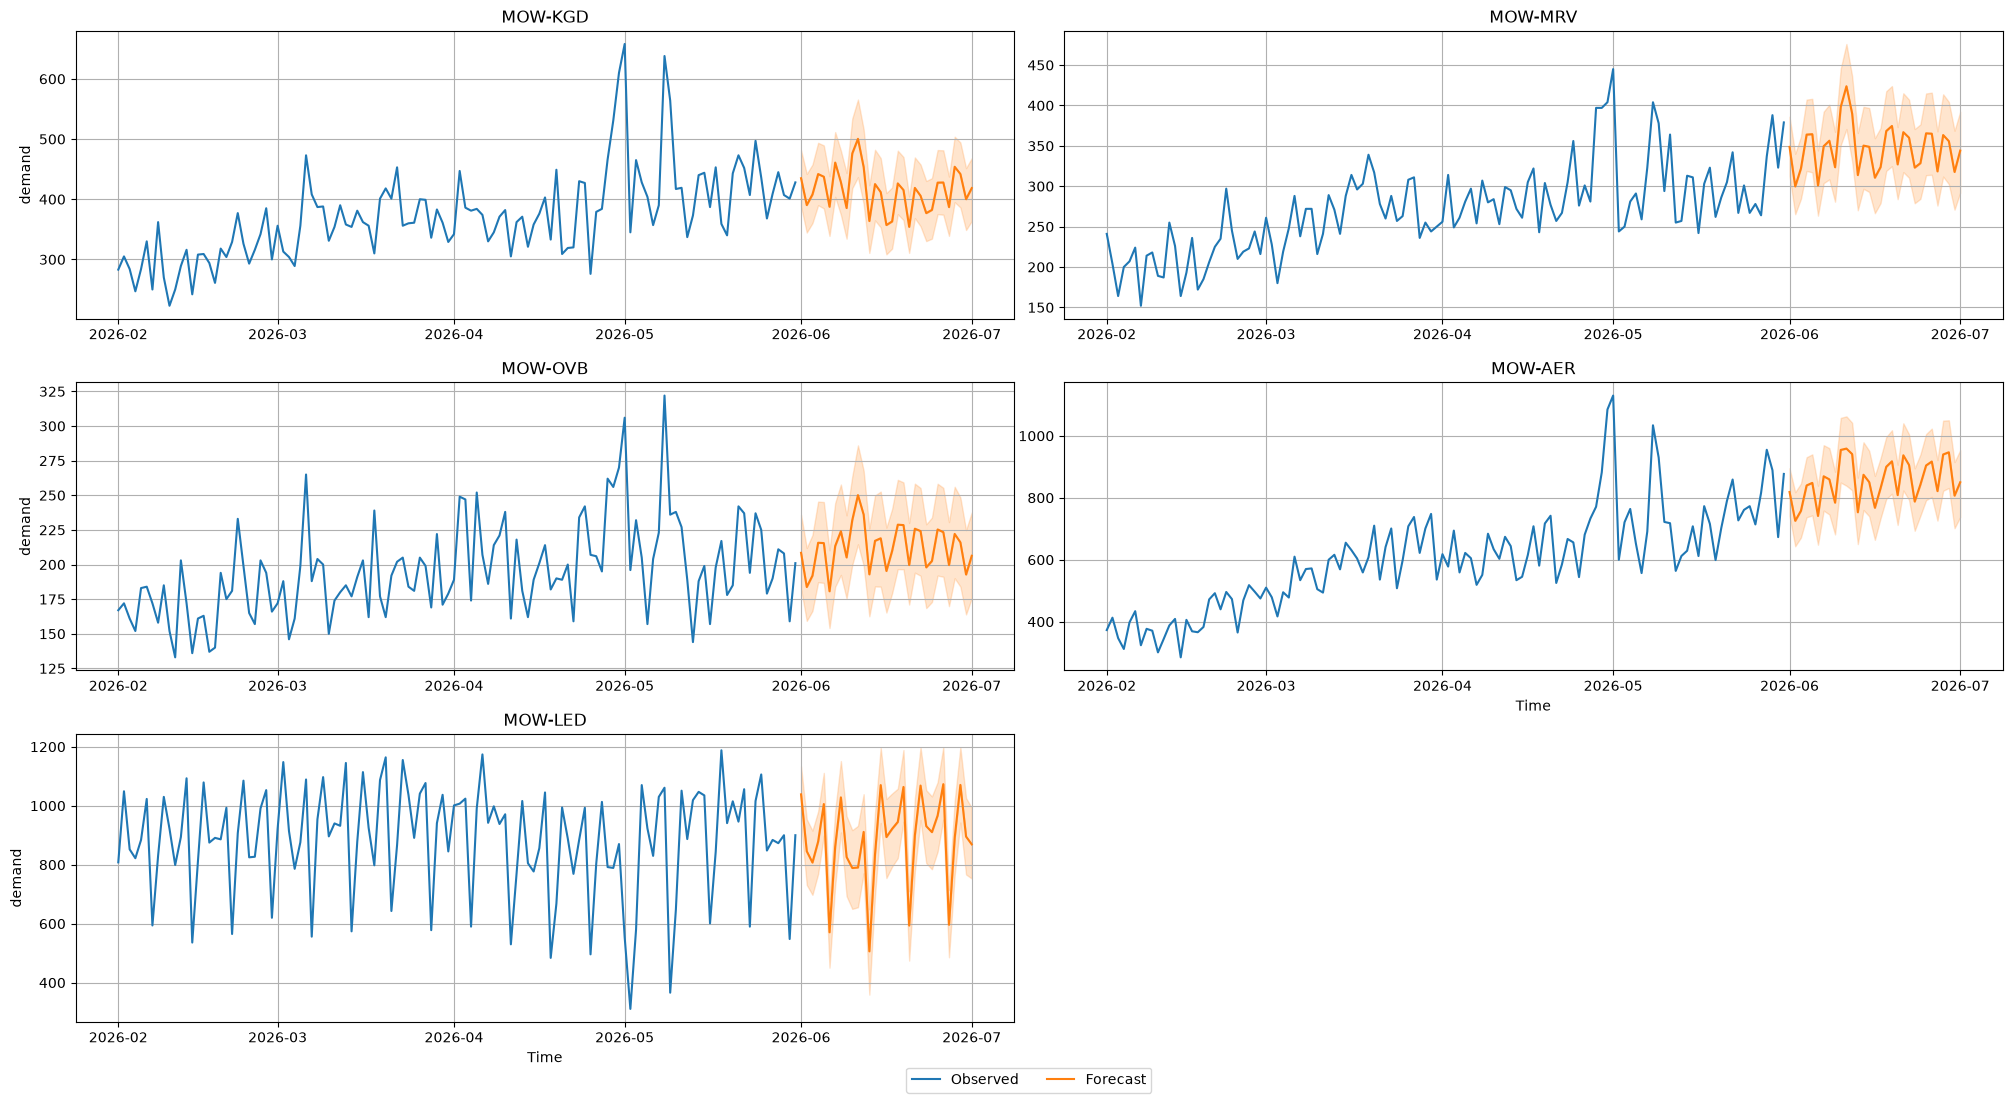

Ширина интервала 0.1-0.9: первая неделя июня vs последняя
         1-7 июня  25 июня - 1 июля
item_id                            
MOW-AER     185.0             215.0
MOW-KGD     100.0             105.0
MOW-LED     221.0             245.0
MOW-MRV      82.0              99.0
MOW-OVB      56.0              63.0


In [10]:
# Ваш код здесь
# Подсказка: predictor.plot(история, прогноз, quantile_levels=[0.1, 0.9], max_history_length=...)
predictor.plot(history_ts, predictions, quantile_levels=[0.1, 0.9], max_history_length=120, max_num_item_ids=5)
plt.show()

width = (predictions["0.9"] - predictions["0.1"]).groupby(level="item_id")
print("Ширина интервала 0.1-0.9: первая неделя июня vs последняя")
print(pd.DataFrame({"1-7 июня": width.apply(lambda s: s.iloc[:7].mean()),
                    "25 июня - 1 июля": width.apply(lambda s: s.iloc[-7:].mean())}).round(0))

**Ваш ответ:** Как вам прогноз визуально? Похож ли он на историю? Почему интервал расширяется со временем?

**Визуально прогноз правдоподобен**: уровень продолжает историю (начало летнего сезона, спрос у туристических маршрутов выше весеннего). У Петербурга сохраняется недельный узор с провалами по субботам. Модель воспроизводит **пик 10–11 июня** у туристических маршрутов (канун длинных выходных 12 июня): например, у Сочи 955–959 против ~850 в обычные дни. У Петербурга праздник 12 июня (пятница) учтён **слабее, чем нужно**: прогноз 911 против ~1006 в обычную пятницу (−9%), а в истории праздничный день давал ×0,6–0,7. Модель недооценивает праздничный провал делового маршрута, поэтому цены на этот рейс стоит проверить вручную.

**Почему интервал расширяется со временем.** Чем дальше прогноз, тем больше неопределённость: на завтра модель знает текущий уровень спроса, а за месяц уровень может уйти вверх или вниз, ошибки накапливаются, могут случиться непредсказуемые события. Поэтому сценарии 0.1–0.9 расходятся. У Chronos-2 расширение умеренное: ширина интервала в первую неделю июня, например у Сочи, ~185 человек, в последнюю ~215. У DirectTabular интервал к концу месяца раздувался почти втрое. Это ещё один довод в пользу выбора Chronos-2 для цен.


## Задание 7. Как из прогноза спроса получается цена

Обязательно запустите все ячейки этого задания: в конце получится файл с прогнозом спроса и ценами, который понадобится
в части кейса Разработка.

В этом задании ничего писать не нужно, весь код уже готов. Здесь мы разберём, как сервис по вашему прогнозу спроса
подбирает цену билета.

### 7.1. Цена для одного рейса: перебор

Возьмём один рейс - Москва - Сочи, 12 июня - и медианный прогноз спроса для него (квантиль 0.5). Это спрос
**при базовой цене**. Если цену изменить, спрос тоже изменится:

```
спрос(цена) = прогноз спроса − чувствительность × (цена − базовая цена)
```

Например, у Сочи чувствительность 0.141: если поднять цену на 1 000 ₽, лететь захотят примерно на 141 человека меньше.

Продать больше билетов, чем мест в самолёте, нельзя:

```
продано = min(спрос(цена), мест в самолёте)
```

А прибыль - это то, что остаётся с каждого билета после расходов, умноженное на число проданных билетов:

```
прибыль = (цена − расходы на пассажира) × продано
```

Почему у прибыли есть максимум:
- **слишком низкая цена** - билеты раскупят, но с каждого мы заработаем мало;
- **слишком высокая цена** - с каждого билета заработаем много, но покупателей почти не останется.

Лучшая цена где-то посередине. Чтобы её найти, переберём все цены с шагом 100 ₽ и выберем ту, при которой прибыль
наибольшая.

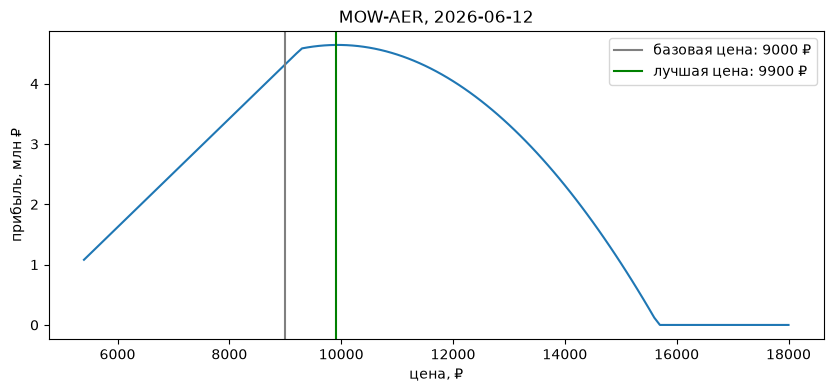

In [11]:
schedule = pd.read_csv(DATA_DIR + "schedule.csv", parse_dates=["date"])

route, day = "MOW-AER", pd.Timestamp("2026-06-12")
info = routes[routes["route"] == route].iloc[0]                                   # параметры маршрута
seats = schedule[(schedule["route"] == route) & (schedule["date"] == day)]["seats"].iloc[0]
demand_base = predictions.loc[(route, day), "0.5"]                                # медианный прогноз спроса

prices = np.arange(info["price_min"], info["price_max"] + 1, 100)                # все цены с шагом 100 ₽
demand = np.maximum(0, demand_base - info["price_sensitivity"] * (prices - info["base_price"]))
sold = np.minimum(demand, seats)
profit = (prices - info["cost_per_passenger"]) * sold
best_price = prices[profit.argmax()]

plt.figure(figsize=(10, 4))
plt.plot(prices, profit / 1e6)
plt.axvline(info["base_price"], color="gray", label=f"базовая цена: {info['base_price']} ₽")
plt.axvline(best_price, color="green", label=f"лучшая цена: {best_price} ₽")
plt.xlabel("цена, ₽"); plt.ylabel("прибыль, млн ₽"); plt.title(f"{route}, {day.date()}")
plt.legend(); plt.show()

### 7.2. Та же цена - по формуле

Перебирать цены не обязательно: лучшую цену можно посчитать сразу, школьной математикой.

**Пока мест хватает**, прибыль зависит от цены как парабола:

```
прибыль(цена) = (цена − расходы) × (прогноз − чувствительность × (цена − базовая цена))
```

Она обращается в ноль в двух точках:
- когда цена равна расходам - с билета ничего не зарабатываем;
- когда цена так высока, что желающих не остаётся: `базовая цена + прогноз / чувствительность`.

Вершина параболы лежит ровно посередине между этими точками:

```
вершина = (расходы + базовая цена + прогноз / чувствительность) / 2
```

**Если желающих больше, чем мест**, цену выгодно поднимать, пока самолёт не начнёт пустеть: всё равно продадим все
места, но дороже. Цена, при которой самолёт ровно заполняется:

```
цена_полного_самолёта = базовая цена + (прогноз − мест) / чувствительность
```

**Лучшая цена** - большая из этих двух, но не выходящая за допустимый диапазон от `price_min` до `price_max`. Проверим,
что формула даёт то же, что и перебор (перебор шёл с шагом 100 ₽, поэтому совпадение - с точностью до 100 ₽).

In [12]:
def optimal_price(demand_base, info, seats):
    """Лучшая цена для одного сценария спроса - по формуле, без перебора."""
    b, p0, cost = info["price_sensitivity"], info["base_price"], info["cost_per_passenger"]
    top_of_parabola = (cost + p0 + demand_base / b) / 2       # вершина параболы (мест хватает)
    full_plane = p0 + (demand_base - seats) / b                # самолёт заполнен ровно
    price = max(top_of_parabola, full_plane)
    return min(max(price, info["price_min"]), info["price_max"])   # не выходим за допустимый диапазон

print("перебор:", best_price, "₽")
print("формула:", round(optimal_price(demand_base, info, seats)), "₽")

перебор: 9900 ₽
формула: 9937 ₽


### 7.3. От квантилей спроса - к распределению цены

До сих пор мы считали цену только для медианного прогноза (квантиль 0.5). Но модель выдаёт 9 сценариев спроса,
от пессимистичного 0.1 до оптимистичного 0.9. Посчитаем лучшую цену для каждого из них.

Чем больше спрос, тем выше лучшая цена. Поэтому из 9 сценариев спроса получается 9 сценариев цены - это и есть
**распределение цены**, о котором шла речь в начале:
- если цены в разных сценариях близки, модель уверена и цену можно ставить смело;
- если разброс большой, на рейс стоит посмотреть внимательнее и выбрать менее рискованную цену.

Для каждого сценария посчитаем, сколько билетов продадим по лучшей цене и какой будет прибыль. Для сравнения - прибыль,
если оставить базовую цену.

In [13]:
QUANTILES = ["0.1", "0.2", "0.3", "0.4", "0.5", "0.6", "0.7", "0.8", "0.9"]

rows = []
for q in QUANTILES:
    d = predictions.loc[(route, day), q]                          # спрос при базовой цене в этом сценарии
    price = optimal_price(d, info, seats)
    sold_q = min(max(0, d - info["price_sensitivity"] * (price - info["base_price"])), seats)
    sold_base = min(d, seats)                                     # продажи, если оставить базовую цену
    rows.append({
        "квантиль": q,
        "спрос при базовой цене": round(d),
        "лучшая цена, ₽": round(price),
        "продано": round(sold_q),
        "прибыль, млн ₽": round((price - info["cost_per_passenger"]) * sold_q / 1e6, 2),
        "прибыль при базовой цене, млн ₽": round((info["base_price"] - info["cost_per_passenger"]) * sold_base / 1e6, 2),
    })
pd.DataFrame(rows)

,квантиль,спрос при базовой цене,"лучшая цена, ₽",продано,"прибыль, млн ₽","прибыль при базовой цене, млн ₽"
0,0.1,824,9523,751,4.00,3.96
1,0.2,868,9679,773,4.23,4.17
2,0.3,896,9777,786,4.38,4.30
3,0.4,919,9859,798,4.52,4.32
4,0.5,941,9937,809,4.64,4.32
5,0.6,959,10002,818,4.75,4.32
6,0.7,978,10070,828,4.86,4.32
7,0.8,1002,10153,839,5.00,4.32
8,0.9,1042,10296,860,5.24,4.32


### 7.4. Все рейсы и файл для сервиса

Теперь посчитаем то же самое для всех маршрутов и всех дней июня. Для каждого рейса и каждого из 9 сценариев получим
спрос при базовой цене, лучшую цену и спрос при лучшей цене. Результат сохраним в файл `my_forecast.csv`, его и нужно будет использовать в части Разработка.

Колонки файла:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `date` | дата рейса |
| `seats` | сколько мест в самолётах |
| `0.1_base_demand` … `0.9_base_demand` | спрос при базовой цене в каждом сценарии |
| `0.1_price` … `0.9_price` | лучшая цена в каждом сценарии, ₽ |
| `0.1_price_demand` … `0.9_price_demand` | спрос при лучшей цене (без учёта ограничения по местам) |

In [14]:
rows = []
for (route_i, day_i), forecast_row in predictions.iterrows():          # по одной строке на маршрут и день
    info_i = routes[routes["route"] == route_i].iloc[0]
    seats_i = schedule[(schedule["route"] == route_i) & (schedule["date"] == day_i)]["seats"].iloc[0]
    row = {"route": route_i, "date": day_i.strftime("%Y-%m-%d"), "seats": seats_i}
    for q in QUANTILES:
        d = forecast_row[q]
        price = optimal_price(d, info_i, seats_i)
        row[f"{q}_base_demand"] = round(d)                                                        # спрос при базовой цене
        row[f"{q}_price"] = round(price)                                                          # лучшая цена
        row[f"{q}_price_demand"] = round(max(0, d - info_i["price_sensitivity"] * (price - info_i["base_price"])))
    rows.append(row)

result = pd.DataFrame(rows)
result.to_csv("my_forecast.csv", index=False)
result.head()

,route,date,seats,0.1_base_demand,0.1_price,0.1_price_demand,0.2_base_demand,0.2_price,0.2_price_demand,0.3_base_demand,...,0.6_price_demand,0.7_base_demand,0.7_price,0.7_price_demand,0.8_base_demand,0.8_price,0.8_price_demand,0.9_base_demand,0.9_price,0.9_price_demand
0,MOW-AER,2026-06-01,900,742,9231,709,768,9324,723,786,...,755,849,9609,763,868,9679,772,895,9775,786
1,MOW-AER,2026-06-02,900,644,8882,660,672,8982,674,691,...,710,762,9301,719,786,9388,731,818,9501,747
2,MOW-AER,2026-06-03,900,672,8981,674,702,9088,689,723,...,727,795,9419,736,817,9497,747,846,9599,761
3,MOW-AER,2026-06-04,900,737,9214,707,774,9345,725,800,...,767,877,9708,777,899,9788,788,931,9901,804
4,MOW-AER,2026-06-05,900,743,9235,710,781,9369,729,808,...,771,885,9738,781,909,9822,793,940,9934,808


Посмотрим на один маршрут целиком. Сверху - спрос при базовой цене и спрос при лучшей цене вместе с числом мест
в самолётах, снизу - лучшая цена и базовая цена. Видно, как цена следует за спросом: где спрос высокий, цену поднимаем,
и желающих становится меньше.

**Результат задания:** запущенные ячейки и файл `my_forecast.csv`.

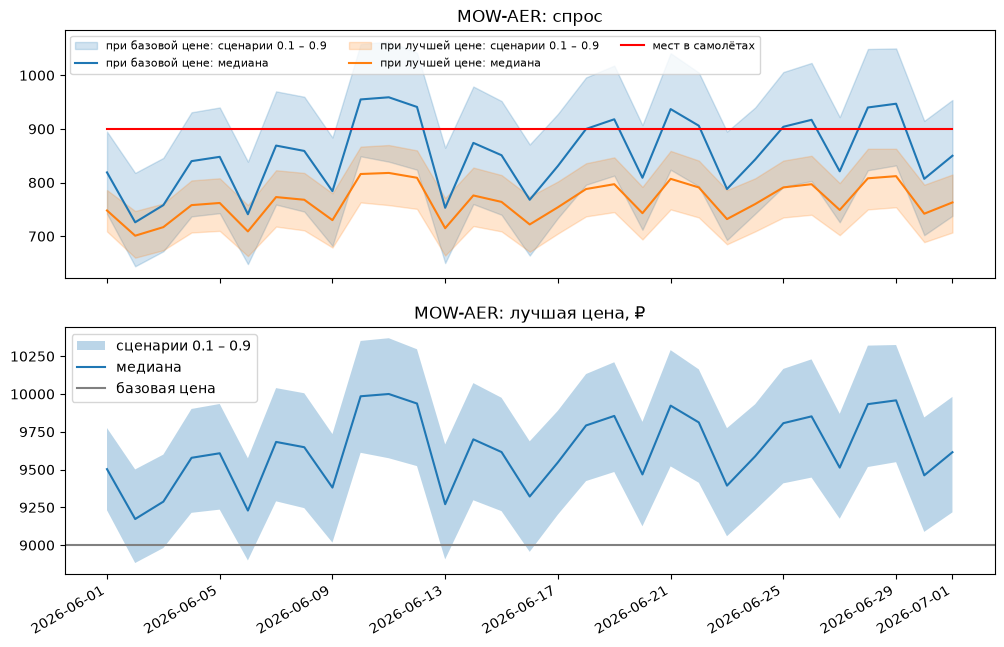

In [15]:
one = result[result["route"] == "MOW-AER"]
dates = pd.to_datetime(one["date"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.fill_between(dates, one["0.1_base_demand"], one["0.9_base_demand"], color="C0", alpha=0.2,
                 label="при базовой цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_base_demand"], color="C0", label="при базовой цене: медиана")
ax1.fill_between(dates, one["0.1_price_demand"], one["0.9_price_demand"], color="C1", alpha=0.2,
                 label="при лучшей цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_price_demand"], color="C1", label="при лучшей цене: медиана")
ax1.plot(dates, one["seats"], color="red", label="мест в самолётах")
ax1.set_title("MOW-AER: спрос"); ax1.legend(fontsize=8, ncol=3)

ax2.fill_between(dates, one["0.1_price"], one["0.9_price"], alpha=0.3, label="сценарии 0.1 – 0.9")
ax2.plot(dates, one["0.5_price"], label="медиана")
ax2.axhline(routes[routes["route"] == "MOW-AER"]["base_price"].iloc[0], color="gray", label="базовая цена")
ax2.set_title("MOW-AER: лучшая цена, ₽"); ax2.legend()
fig.autofmt_xdate()                                    # наклоняем подписи дат, чтобы не наезжали
plt.show()

## Готово!

Сдайте:
1. этот ноутбук с вашим кодом и ответами на вопросы;
2. файл `my_forecast.csv` из задания 7 - используйте его в части кейса Разработка.